# 09 – Zählung: von gemeldeter Fläche zu Parkplätzen

**Ziel.** Für jeden Testausschnitt drei Zahlen nebeneinanderstellen:

| Zahl | Woher |
| --- | --- |
| **Methode** | gemeldete Fläche des Netzes (Notebook 08) ÷ Platzfläche (Notebook 03) |
| **Ground Truth** | vom Auftraggeber gesetzte Felder (Notebook 04) |
| **amtlich** | Versuch A: Strassenparkplätze der Stadt, Stand 31.12.2021; Versuch B: DAV-Punkte 2025 |

**Warum.** Das ist der Kern des Versuchs: Wie gross ist das Delta zwischen dem, was die Methode zählt, und den wirklichen Daten? Dieses Notebook stellt die Zahlen bereit; verglichen und gedeutet wird in Notebook 10. Eingestellt wird hier nichts mehr.

**Die Zählformel** ist dieselbe, die in Notebook 05 am Lösungsblatt geprüft wurde (`01b`, Abschnitt 11, E7).

**Zwei Mengen.** Alles wird zweimal gezählt:

| Menge | Inhalt | wozu |
| --- | --- | --- |
| **alle** | jedes Feld im Testausschnitt, auf jedem Grund | Wie gut findet die Methode aufgemalte Felder? |
| **Vergleichsraum** | nur Felder im Strassenraum (`01b`, E2) **und** im Gebiet | nur hier darf mit amtlichen Daten verglichen werden |

**Eingaben:** Masken (Notebook 08), Kategorie je Pixel (Notebook 05), `kaestchen.gpkg` und `strassenraum.gpkg` (Notebook 04), `platzmasse.json` (Notebook 03), DAV-Punkte (Notebook 01), Strassenparkplätze 2021 (Rohdaten).
**Ausgaben:** `ergebnisse/zaehlung.csv` (eine Zeile je Lauf und Testausschnitt), Abbildung `09_flaechen.png`.

In [1]:
import json                        # Einstellungen und Platzmasse lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, VERSUCHE, AUFLOESUNGEN_CM, CODE = EINST["CRS"], EINST["VERSUCHE"], EINST["AUFLOESUNGEN_CM"], EINST["CODE"]
MASSE = json.loads((VERARB / "platzmasse.json").read_text(encoding="utf-8"))    # Platzmasse aus Notebook 03
KACHEL_M = 51.2                                      # Seitenlänge eines Ausschnitts
print("Platzfläche eng:", MASSE["eng"]["flaeche_m2"], "m² | weit:", MASSE["weit"]["flaeche_m2"], "m² | Grenze der Tiefe:", MASSE["TIEFE_GRENZE_M"], "m")

import numpy as np                 # Pixelraster
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
from rasterio.features import shapes, rasterize    # Raster zurück in Formen; Formen in ein Raster zeichnen
from rasterio.transform import from_origin         # Lage eines Rasters festlegen
from shapely.geometry import shape                 # Form aus einer Beschreibung

Platzfläche eng: 12.48 m² | weit: 10.66 m² | Grenze der Tiefe: 3.45 m


## 1. Testausschnitte, Strassenraum und Gebiet

**Schritt 1: lesen.** Die Testausschnitte (Notebook 02), die Grundstücke im Strassenraum (Notebook 04) und das Gebiet (Notebook 00).

**Schritt 2: eine Hilfe für später.** Für Punkte (Ringe, amtliche Punkte, Mittelpunkte gemeldeter Flächen) brauchen wir immer dieselbe Frage: Liegt der Punkt im **Vergleichsraum**, also im Strassenraum und im Gebiet? `sjoin` prüft, ob ein Punkt in einem Strassenraum-Grundstück liegt; `within` prüft das Gebiet.

In [2]:
aufteilung = pd.read_csv(VERARB / "aufteilung.csv")
test = aufteilung[aufteilung.gruppe == "testen"].set_index("kachel")          # Testausschnitte, Kennung als Index
strassenraum = gpd.read_file(VERARB / "strassenraum.gpkg")[["geometry"]]       # Grundstücke im Strassenraum (Notebook 04)
gebiet = gpd.read_file(VERARB / "gebiet.geojson").geometry.iloc[0]             # Fläche des Gebiets (Notebook 00)

def im_vergleichsraum(x, y):
    # True für jeden Punkt, der in einem Strassenraum-Grundstück und im Gebiet liegt
    punkte = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs=CRS)
    treffer = gpd.sjoin(punkte, strassenraum, how="left", predicate="within")  # index_right ist leer, wenn kein Grundstück passt
    in_strasse = treffer[~treffer.index.duplicated()].index_right.notna().values
    return in_strasse & punkte.within(gebiet).values

In [3]:
def ausschnitt_von(x, y):
    # Kennung des Ausschnitts, in dem ein Punkt liegt (wie im Werkzeug: Koordinate ÷ Seitenlänge, abgerundet)
    return "k_" + (x // KACHEL_M).astype(int).astype(str) + "_" + (y // KACHEL_M).astype(int).astype(str)

print(f"Testausschnitte: {len(test)} in {test.block.nunique()} Blöcken | Strassenraum-Grundstücke: {len(strassenraum)}")

Testausschnitte: 137 in 15 Blöcken | Strassenraum-Grundstücke: 425


## 2. Die Ground Truth je Testausschnitt

**Schritt 1: Felder der Testausschnitte mit ihrer Menge.** Jedes Feld bekommt die Angabe, ob es im Vergleichsraum liegt.

**Schritt 2: zählen.** Je Versuch (Bild) und Ausschnitt zählen wir die Felder je Kategorie. `pd.crosstab` macht daraus eine Tabelle: eine Zeile je Ausschnitt, eine Spalte je Kategorie.

**Schritt 3: Sonderfelder getrennt.** Zwei Formen aus dem Werkzeug sind Sonderfelder (`01b`, 8.5 D4): `✕` (Taxi, Polizei, Feld mit Kreuz) und `?` (Invalidenparkplatz). Sie zählen wie gewöhnliche Felder und sind in `wahr` enthalten. Die Spalten `wahr_kreuz` und `wahr_fragezeichen` sagen, wie viele der sichtbaren Felder es sind (Nachtrag vom 27.11.2026, `01b`, Abschnitt 11.2, N1).

Vorher: Felder → nachher: je Versuch eine Tabelle mit den wahren Zahlen je Testausschnitt.

In [4]:
felder = gpd.read_file(VERARB / "kaestchen.gpkg", ignore_geometry=True)        # Felder mit Kategorie je Bild (Notebook 04)
felder = felder[felder.kachel.isin(test.index)].copy()                         # nur Felder der Testausschnitte
felder["vergleich"] = im_vergleichsraum(felder.x, felder.y)
print(f"Felder in Testausschnitten: {len(felder)} → davon im Vergleichsraum: {int(felder.vergleich.sum())}")

SONDER = {"gelbes Feld mit Kreuz": "kreuz", "unklar": "fragezeichen"}          # Formen der Sonderfelder und ihr Spaltenname
wahrheit = {}                                                                  # je Versuch eine Tabelle
for versuch, angaben in VERSUCHE.items():
    spalte = angaben["kategorie"]
    alle = pd.crosstab(felder.kachel, felder[spalte])                          # Felder je Ausschnitt und Kategorie, alle
    im_raum = pd.crosstab(felder[felder.vergleich].kachel, felder[felder.vergleich][spalte])   # dasselbe, nur Vergleichsraum
    tabelle = pd.DataFrame(index=test.index)
    tabelle["wahr"] = alle.get("sichtbar")                                     # sichtbare Felder, alle
    tabelle["wahr_vergleich"] = im_raum.get("sichtbar")                        # sichtbare Felder im Vergleichsraum
    tabelle["wahr_verdeckt_belegt_vergleich"] = im_raum.get("verdeckt, belegt")
    tabelle["wahr_einzeln_vergleich"] = im_raum.get("einzeln")
    tabelle["wahr_unsicher_vergleich"] = im_raum.get("unsicher")
    tabelle["wahr_streifen"] = alle.get("Streifen")                            # von Hand geschätzte Plätze in Streifen
    sichtbar = felder[felder[spalte] == "sichtbar"]                            # Schritt 3: sichtbare Felder dieses Bildes
    for form, kurz in SONDER.items():
        tabelle[f"wahr_{kurz}"] = sichtbar[sichtbar.form == form].kachel.value_counts()                              # davon Sonderfelder, alle
        tabelle[f"wahr_{kurz}_vergleich"] = sichtbar[(sichtbar.form == form) & sichtbar.vergleich].kachel.value_counts()   # ... im Vergleichsraum
    wahrheit[versuch] = tabelle.fillna(0).astype(int)                          # Ausschnitte ohne Feld: 0
pd.DataFrame({versuch: tabelle.sum() for versuch, tabelle in wahrheit.items()})

Felder in Testausschnitten: 846 → davon im Vergleichsraum: 435


,A,B
wahr,708,500
wahr_vergleich,360,266
wahr_verdeckt_belegt_vergleich,3,46
wahr_einzeln_vergleich,8,1
wahr_unsicher_vergleich,10,35
wahr_streifen,58,55
wahr_kreuz,44,30
wahr_kreuz_vergleich,30,24
wahr_fragezeichen,7,5
wahr_fragezeichen_vergleich,0,0


## 3. Die amtlichen Daten je Testausschnitt

**Schritt 1: lesen und auf den Vergleichsraum beschränken.** Jeder Versuch wird mit den amtlichen Daten **seines** Jahres verglichen (`01b`, Abschnitt 3 und Abschnitt 11, E11):
- Versuch A: Strassenparkplätze der Stadt, Stand 31.12.2021, ohne die Art "Blaue Zone" (sie kommt im Gebiet nur als Streifen vor, und Streifen zählen wir nicht);
- Versuch B: die Punkte der DAV, Stand 2025.

Vorher: amtliche Punkte der ganzen Stadt → nachher: Anzahl je Testausschnitt, nur Vergleichsraum.

In [5]:
stadt_2021 = gpd.read_file(ROH / "parkplaetze/Strassenparkplaetze_OGD_2021_view_pp_ogd.geojson").to_crs(CRS).explode(index_parts=False)
stadt_2021 = stadt_2021[stadt_2021.art != "Blaue Zone"]                        # Streifen bleiben weg
dav_2025 = gpd.read_file(VERARB / "dav_punkte.gpkg")                           # DAV-Punkte (Notebook 01)

amtlich = {}
for versuch, punkte in [("A", stadt_2021), ("B", dav_2025)]:
    punkte = punkte[punkte.within(gebiet)]                                     # nur das Gebiet
    x, y = punkte.geometry.x, punkte.geometry.y
    im_raum = im_vergleichsraum(x, y)
    je_ausschnitt = ausschnitt_von(x, y)[im_raum].value_counts()               # Punkte im Vergleichsraum je Ausschnitt
    amtlich[versuch] = je_ausschnitt.reindex(test.index).fillna(0).astype(int)
    print(f"Versuch {versuch}: {len(punkte)} amtliche Punkte im Gebiet → {int(im_raum.sum())} im Vergleichsraum → {int(amtlich[versuch].sum())} in Testausschnitten")

Versuch A: 1510 amtliche Punkte im Gebiet → 1440 im Vergleichsraum → 354 in Testausschnitten
Versuch B: 1252 amtliche Punkte im Gebiet → 1204 im Vergleichsraum → 275 in Testausschnitten


## 4. Von der Maske zu Flächen: ein Ausschnitt Schritt für Schritt

**Schritt 1: die Meldung nach der Lösung aufteilen.** Die Kategorie je Pixel (Notebook 05) sagt, wo ein Feld verdeckt ist oder ein Streifen liegt. Was das Netz dort meldet, zählt **nicht** als erkannt, sondern wird getrennt ausgewiesen (`01b`, 8.4 V5):

| Teil der Meldung | Kategorie der Lösung | zählt als |
| --- | --- | --- |
| `bewertet` | 0 (keine Parkfläche) oder 1 (sichtbar) | **erkannt** |
| `verdeckt` | verdeckt, mit oder ohne Beleg | unter Verdeckung gemeldet |
| `streifen` | Streifen | auf Streifen gemeldet |
| – | unsicher, einzeln | nicht gezählt |

In [6]:
TEILE = {"bewertet": [CODE["kein Parkfeld"], CODE["sichtbar"]], "verdeckt": [CODE["verdeckt, belegt"], CODE["verdeckt"]], "streifen": [CODE["Streifen"]]}

def lies_karten(lauf, kachel):
    # gemeldete Parkfläche (Notebook 08) und Kategorie je Pixel (Notebook 05) eines Testausschnitts
    gemeldet = np.load(ERG / "masken" / lauf / f"{kachel}.npz")["gemeldet"]
    kategorie = np.load(VERARB / "loesung" / lauf / f"{kachel}.npz")["kategorie"]
    return gemeldet, kategorie

beispiel = wahrheit["A"].wahr.idxmax()                              # Testausschnitt mit den meisten sichtbaren Feldern (Bild 2021)
gemeldet, kategorie = lies_karten("A_5cm", beispiel)
for teil, codes in TEILE.items():
    print(f"{teil:9s}: {int((gemeldet & np.isin(kategorie, codes)).sum()) * 0.05 ** 2:8.1f} m² gemeldet")

bewertet :    387.1 m² gemeldet
verdeckt :     10.4 m² gemeldet
streifen :      4.3 m² gemeldet


**Schritt 2: zusammenhängende Flächen und ihre Klasse.** Genau die Formel aus Notebook 05: Jede zusammenhängende Fläche bekommt ihre mittlere Tiefe (Fläche ÷ lange Seite des kleinsten umschliessenden Rechtecks), daraus die Klasse und die Platz-Äquivalente. Neu ist nur der Mittelpunkt der Fläche in Landeskoordinaten: Mit ihm wird später entschieden, ob die Fläche im Vergleichsraum liegt.

In [7]:
def flaechen_tabelle(maske, kachel, pixel_m):
    # Zerlegt eine Maske in zusammenhängende Flächen. Je Fläche: Grösse, mittlere Tiefe, Klasse, Platz-Äquivalente, Mittelpunkt
    links, oben = test.i[kachel] * KACHEL_M, (test.j[kachel] + 1) * KACHEL_M   # linke obere Ecke des Ausschnitts in Metern
    zeilen = []
    for beschreibung, _ in shapes(maske.astype("uint8"), mask=maske, transform=from_origin(links, oben, pixel_m, pixel_m)):
        flaeche = shape(beschreibung)                                # eine zusammenhängende Fläche in Landeskoordinaten
        ecken = np.array(flaeche.minimum_rotated_rectangle.exterior.coords)    # kleinstes umschliessendes Rechteck
        kanten = ecken[1:3] - ecken[0:2]                             # seine zwei Kanten als Vektoren
        tiefe = flaeche.area / np.hypot(kanten[:, 0], kanten[:, 1]).max()      # mittlere Tiefe
        klasse = "eng" if tiefe > MASSE["TIEFE_GRENZE_M"] else "weit"
        zeilen.append(dict(flaeche_m2=flaeche.area, tiefe_m=tiefe, klasse=klasse, aequivalente=flaeche.area / MASSE[klasse]["flaeche_m2"],
                           x=flaeche.centroid.x, y=flaeche.centroid.y, form=flaeche))
    return zeilen

beispiel_flaechen = pd.DataFrame(flaechen_tabelle(gemeldet & np.isin(kategorie, TEILE["bewertet"]), beispiel, 0.05))
print(f"Beispiel {beispiel}: {len(beispiel_flaechen)} Flächen, zusammen {beispiel_flaechen.aequivalente.sum():.2f} Platz-Äquivalente "
      f"→ gerundet {int(np.floor(beispiel_flaechen.aequivalente.sum() + 0.5))} | sichtbare Felder laut Ground Truth: {int(wahrheit['A'].wahr[beispiel])}")
beispiel_flaechen.drop(columns="form").sort_values("flaeche_m2", ascending=False).head(6).round(2)

Beispiel k_52402_24353: 343 Flächen, zusammen 31.82 Platz-Äquivalente → gerundet 32 | sichtbare Felder laut Ground Truth: 33


,flaeche_m2,tiefe_m,klasse,aequivalente,x,y
187,328.27,9.90,eng,26.30,2683003.29,1246910.55
324,35.98,2.76,weit,3.37,2682985.40,1246880.39
337,21.86,1.82,weit,2.05,2683018.53,1246877.42
342,0.04,0.09,weit,0.00,2683013.28,1246873.68
302,0.02,0.11,weit,0.00,2682986.38,1246875.85
37,0.01,0.05,weit,0.00,2682993.80,1246917.02


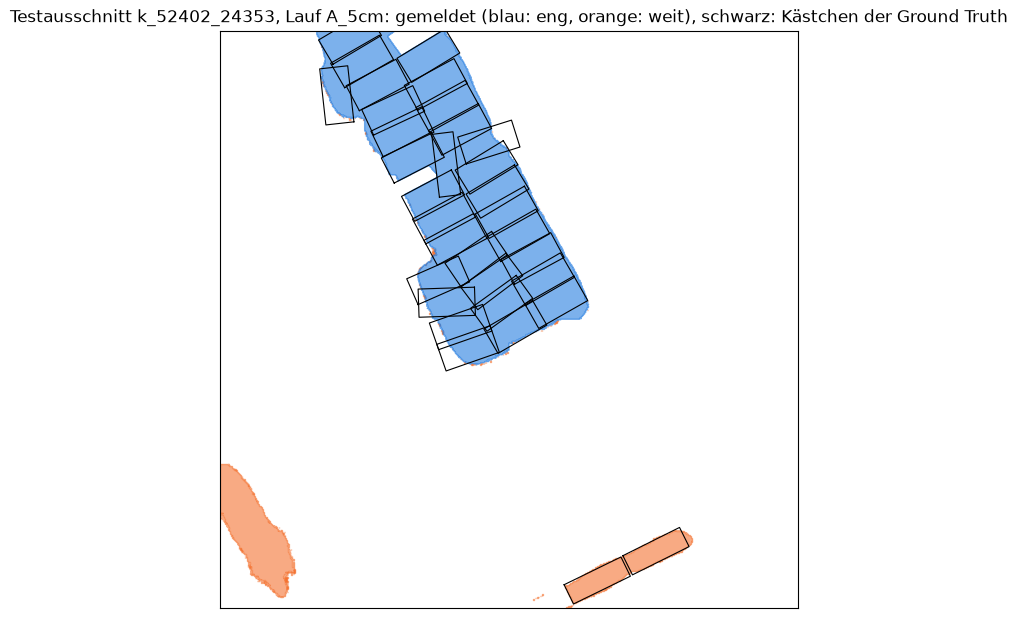

In [8]:
# Abbildung: gemeldete Flächen des Beispiel-Ausschnitts, gefärbt nach Klasse; darüber die Kästchen der Ground Truth
kaestchen = gpd.read_file(VERARB / "kaestchen.gpkg")
kaestchen = kaestchen[(kaestchen.kachel == beispiel) & (kaestchen.kat_2021 == "sichtbar")]
FARBE = {"eng": "#257de0", "weit": "#f47230"}                        # Projektfarben der Klassen
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for flaeche in beispiel_flaechen.itertuples():
    ax.fill(*flaeche.form.exterior.xy, color=FARBE[flaeche.klasse], alpha=0.6)   # gemeldete Fläche
for umriss in kaestchen.geometry:
    ax.plot(*umriss.exterior.xy, color="black", linewidth=0.8)       # Kästchen der Ground Truth
links, oben = test.i[beispiel] * KACHEL_M, (test.j[beispiel] + 1) * KACHEL_M
ax.set_xlim(links, links + KACHEL_M); ax.set_ylim(oben - KACHEL_M, oben)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Testausschnitt {beispiel}, Lauf A_5cm: gemeldet (blau: eng, orange: weit), schwarz: Kästchen der Ground Truth")
fig.savefig(ABB / "09_flaechen.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Farbig: was das Netz als Parkfläche meldet, blau für tiefe Flächen (Klasse `eng`), orange für schmale (Klasse `weit`). Schwarz umrandet: die Kästchen der sichtbaren Felder. Decken sich Farbe und Kästchen, hat das Netz die Fläche gefunden.

## 5. Alle Testausschnitte, alle vier Läufe

**Schritt 1: alle Flächen sammeln.** Für jeden Lauf und jeden Testausschnitt dieselben Schritte wie in Abschnitt 4, für alle drei Teile der Meldung.

**Eine Kontrolle läuft mit.** Wir zerlegen auch das **Lösungsblatt selbst** (Teil `loesung`: alle Pixel der Kategorie `sichtbar`). Das beantwortet: Was würde die Zählformel in diesem Testausschnitt zählen, wenn das Netz die Fläche perfekt träfe? Der Unterschied zur Zahl der gesetzten Felder ist der Fehler der Formel allein. Er steht später neben dem Fehler des Netzes.

Nebenbei zählen wir die Pixel für die Güte der Fläche (Notebook 10): richtig erkannt (TP), Fehlmeldung (FP), übersehen (FN), jeweils nur auf bewerteten Pixeln.

**Sonderfelder getrennt.** Für die Trefferquote je Form brauchen wir eine Karte: Welche Pixel liegen in einem sichtbaren Sonderfeld (`✕` oder `?`)? `rasterize` zeichnet die Kästchen dieser Felder in das Raster des Ausschnitts. Damit zählen wir zusätzlich `tp_sonder` und `fn_sonder`: richtig erkannte und übersehene Pixel **in Sonderfeldern**. Wo sich ein Sonderfeld und ein gewöhnliches Feld überlappen, zählt der Pixel zum Sonderfeld.

In [9]:
kaestchen_alle = gpd.read_file(VERARB / "kaestchen.gpkg")                         # Kästchen mit Geometrie (Notebook 04)
sonder_formen = {}                                                               # je Versuch: Kästchen der sichtbaren Sonderfelder
for versuch, angaben in VERSUCHE.items():
    auswahl = kaestchen_alle.form.isin(SONDER) & (kaestchen_alle[angaben["kategorie"]] == "sichtbar")
    sonder_formen[versuch] = kaestchen_alle[auswahl].geometry.tolist()
    print(f"Versuch {versuch}: {len(sonder_formen[versuch])} sichtbare Sonderfelder im ganzen Gebiet")

def sonder_karte(versuch, kachel, pixel_m):
    # True für jeden Pixel des Ausschnitts, der in einem sichtbaren Sonderfeld liegt
    links, oben = test.i[kachel] * KACHEL_M, (test.j[kachel] + 1) * KACHEL_M   # linke obere Ecke des Ausschnitts in Metern
    seite = round(KACHEL_M / pixel_m)                                # 1024 Pixel bei 5 cm, 512 bei 10 cm
    return rasterize(sonder_formen[versuch], out_shape=(seite, seite), transform=from_origin(links, oben, pixel_m, pixel_m)).astype(bool)

sonder = sonder_karte("A", beispiel, 0.05)
print(f"Beispiel {beispiel}: {sonder.mean():.1%} der Pixel liegen in einem sichtbaren Sonderfeld")

Versuch A: 285 sichtbare Sonderfelder im ganzen Gebiet
Versuch B: 192 sichtbare Sonderfelder im ganzen Gebiet
Beispiel k_52402_24353: 1.4% der Pixel liegen in einem sichtbaren Sonderfeld


Vorher: Masken → nachher: eine Tabelle aller gemeldeten Flächen und eine Tabelle der Pixelzahlen.

In [10]:
alle_flaechen, pixel = [], []                                        # zwei Sammellisten
for versuch in VERSUCHE:
    for aufloesung_cm in AUFLOESUNGEN_CM:
        lauf = f"{versuch}_{aufloesung_cm}cm"
        for kachel in test.index:
            gemeldet, kategorie = lies_karten(lauf, kachel)
            for teil, codes in TEILE.items():
                for zeile in flaechen_tabelle(gemeldet & np.isin(kategorie, codes), kachel, aufloesung_cm / 100):
                    zeile.pop("form")                                # die Form wird nicht mehr gebraucht
                    alle_flaechen.append(dict(lauf=lauf, kachel=kachel, teil=teil, **zeile))
            for zeile in flaechen_tabelle(kategorie == CODE["sichtbar"], kachel, aufloesung_cm / 100):   # Kontrolle: das Lösungsblatt selbst
                zeile.pop("form")
                alle_flaechen.append(dict(lauf=lauf, kachel=kachel, teil="loesung", **zeile))
            sonder = sonder_karte(versuch, kachel, aufloesung_cm / 100)          # Pixel in sichtbaren Sonderfeldern
            pixel.append(dict(lauf=lauf, kachel=kachel, tp=int((gemeldet & (kategorie == 1)).sum()),
                              fp=int((gemeldet & (kategorie == 0)).sum()), fn=int((~gemeldet & (kategorie == 1)).sum()),
                              tp_sonder=int((gemeldet & (kategorie == 1) & sonder).sum()), fn_sonder=int((~gemeldet & (kategorie == 1) & sonder).sum())))
        print(lauf, "fertig")
alle_flaechen, pixel = pd.DataFrame(alle_flaechen), pd.DataFrame(pixel)
alle_flaechen["vergleich"] = im_vergleichsraum(alle_flaechen.x, alle_flaechen.y)   # Mittelpunkt im Vergleichsraum?
print(f"Gemeldete Flächen insgesamt: {len(alle_flaechen)}")
alle_flaechen.groupby(["lauf", "teil"]).aequivalente.sum().unstack().round(1)

A_5cm fertig


A_10cm fertig


B_5cm fertig


B_10cm fertig


Gemeldete Flächen insgesamt: 63795


teil,bewertet,loesung,streifen,verdeckt
lauf,,,,
A_10cm,629.4,714.2,14.8,11.2
A_5cm,661.9,715.4,12.5,11.5
B_10cm,394.9,508.3,14.0,50.7
B_5cm,457.1,510.3,13.4,58.8


**Schritt 2: je Ausschnitt summieren und runden.** Die Platz-Äquivalente werden je Lauf und Ausschnitt summiert, einmal für alle Flächen und einmal nur für den Vergleichsraum. Gerundet wird einmal je Ausschnitt: `np.floor(x + 0.5)` rundet kaufmännisch (`01b`, 8.1 K3).

Dann kommen Ground Truth und amtliche Zahl desselben Versuchs in dieselbe Zeile.

Vorher: Tabelle aller Flächen → nachher: eine Zeile je Lauf und Testausschnitt.

In [11]:
def summe_je_ausschnitt(auswahl):
    # Platz-Äquivalente je Lauf und Ausschnitt; Ausschnitte ohne gemeldete Fläche bekommen 0
    alle_zeilen = pd.MultiIndex.from_product([pixel.lauf.unique(), test.index], names=["lauf", "kachel"])
    return auswahl.groupby(["lauf", "kachel"]).aequivalente.sum().reindex(alle_zeilen).fillna(0)

bewertet = alle_flaechen[alle_flaechen.teil == "bewertet"]
zaehlung = pd.DataFrame({
    "aeq": summe_je_ausschnitt(bewertet),                                        # erkannt, alle
    "aeq_vergleich": summe_je_ausschnitt(bewertet[bewertet.vergleich]),          # erkannt, Vergleichsraum
    "aeq_verdeckt_vergleich": summe_je_ausschnitt(alle_flaechen[(alle_flaechen.teil == "verdeckt") & alle_flaechen.vergleich]),
    "aeq_streifen": summe_je_ausschnitt(alle_flaechen[alle_flaechen.teil == "streifen"]),
    "aeq_loesung": summe_je_ausschnitt(alle_flaechen[alle_flaechen.teil == "loesung"]),      # Kontrolle: Formel am Lösungsblatt
}).reset_index()
zaehlung["gezaehlt"] = np.floor(zaehlung.aeq + 0.5).astype(int)                  # einmal je Ausschnitt runden
zaehlung["gezaehlt_vergleich"] = np.floor(zaehlung.aeq_vergleich + 0.5).astype(int)
zaehlung["gezaehlt_loesung"] = np.floor(zaehlung.aeq_loesung + 0.5).astype(int)        # was die Formel bei perfekter Fläche zählt
zaehlung["versuch"] = zaehlung.lauf.str[0]                                       # "A_5cm" -> "A"
zaehlung["aufloesung_cm"] = zaehlung.lauf.str.extract(r"_(\d+)cm")[0].astype(int)
zaehlung["block"] = zaehlung.kachel.map(test.block)
print(f"Vorher: {len(alle_flaechen)} Flächen → nachher: {len(zaehlung)} Zeilen (4 Läufe × {len(test)} Testausschnitte)")

Vorher: 63795 Flächen → nachher: 548 Zeilen (4 Läufe × 137 Testausschnitte)


In [12]:
# Ground Truth und amtliche Zahl des jeweiligen Versuchs dazuhängen, dann die Pixelzahlen
teile = []
for versuch in VERSUCHE:
    stueck = zaehlung[zaehlung.versuch == versuch].merge(wahrheit[versuch], left_on="kachel", right_index=True)
    stueck["amtlich"] = stueck.kachel.map(amtlich[versuch])
    teile.append(stueck)
zaehlung = pd.concat(teile).merge(pixel, on=["lauf", "kachel"])
zaehlung.to_csv(ERG / "zaehlung.csv", index=False)
print("gespeichert: ergebnisse/zaehlung.csv mit", len(zaehlung), "Zeilen")
zaehlung.groupby("lauf")[["wahr", "gezaehlt_loesung", "gezaehlt", "wahr_vergleich", "gezaehlt_vergleich", "amtlich"]].sum()

gespeichert: ergebnisse/zaehlung.csv mit 548 Zeilen


,wahr,gezaehlt_loesung,gezaehlt,wahr_vergleich,gezaehlt_vergleich,amtlich
lauf,,,,,,
A_10cm,708,711,626,360,336,354
A_5cm,708,710,664,360,351,354
B_10cm,500,510,395,266,210,275
B_5cm,500,510,454,266,258,275


**Wie man die Tabelle liest.** Summen über alle Testausschnitte, je Lauf. `wahr` und `gezaehlt` gehören zusammen (alle Felder); `gezaehlt_loesung` ist die Kontrolle (Formel am Lösungsblatt) und sollte nahe bei `wahr` liegen. Ebenso gehören `wahr_vergleich`, `gezaehlt_vergleich` und `amtlich` zusammen (nur Vergleichsraum). Die Deutung, mit Unsicherheit, folgt in Notebook 10.

## Was wir gesehen haben

- Für jeden Lauf und jeden Testausschnitt stehen jetzt drei Zahlen nebeneinander: Methode, Ground Truth, amtlich.
- Was das Netz auf verdeckten Stellen und auf Streifen meldet, ist getrennt ausgewiesen und nicht in `gezaehlt` enthalten.
- Sonderfelder (`✕`, `?`) zählen mit. Wie viele es sind und wie viele ihrer Pixel erkannt wurden, steht in eigenen Spalten.

## Wie es weitergeht

Notebook 10 wertet aus: Wie gut stimmt die Fläche, wie gut die Anzahl, was unterscheidet 5 cm von 10 cm, und wie gross ist das Delta zu den amtlichen Daten?